# 模型選擇 (Model Selection)

##  Model Selection (模型選擇) 是什麼？

Model Selection 就是在多個候選模型或參數組合之間，找出對新資料具有良好預測能力的方案。

過去可能只寫：

```python
model = DecisionTreeRegressor(max_depth=5)
model.fit(X_train, y_train)
```

但為什麼 `max_depth=5`？設定成 3、10 或 20，結果會不會更好？

我們可以手動反覆修改參數，不過這樣不但花時間，也很容易只記得表現最好的那一次結果。

因此，Model Selection 會使用更有系統的方式進行比較。

| 技術                         | 解決的問題                    |
| -------------------------- | ------------------------ |
| Overfitting / Underfitting | 判斷模型太複雜或太簡單              |
| Bias / Variance            | 理解模型誤差與穩定性的來源            |
| K-Fold Cross Validation    | 避免只靠一次資料切分判斷模型好壞         |
| Hyperparameter Tuning      | 調整模型的超參數                 |
| GridSearchCV               | 自動測試不同超參數組合，搭配交叉驗證選出最佳組合 |

## Overfitting&Underfitting (過度擬合與欠擬合)

![](./assets/Overfitting&Underfitting.png)

## Bias / Variance (偏差與變異)

Bias 和 Variance 可以幫助我們理解，為什麼有些模型學得不夠好，有些模型卻學得太細。

![](./assets/Bias&Variance-2.png)

### Bias (偏差)

Bias 可以理解成模型因為假設或結構限制，產生的系統性預測誤差。

例如實際資料呈現彎曲趨勢，但我們硬要使用一條直線去預測，模型就可能出現較高的 Bias。

```text
模型太簡單
    ↓
無法掌握資料規律
    ↓
High Bias
    ↓
容易 Underfitting
```

### Variance (變異)

Variance 指的是模型對訓練資料變動的敏感程度。

假設我們使用兩份略有不同的訓練資料訓練模型：

- 模型 A 的預測結果幾乎沒有改變。
- 模型 B 的預測曲線卻出現很大差異。

模型 B 就可能具有較高的 Variance。

```text
模型過度複雜
    ↓
對訓練資料變動非常敏感
    ↓
High Variance
    ↓
容易 Overfitting
```

![](./assets/Bias&Variance.png)

## K-Fold Cross Validation (K 折交叉驗證)

![](./assets/5-Fold%20Cross%20Validation%20示意.png)



## Hyperparameter Tuning (超參數調整)

![](./assets/Hyperparameters.png)

例如：

```python
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(
    max_depth=5,
    min_samples_leaf=3,
    random_state=42
    # 其中 `max_depth` 與 `min_samples_leaf` 都是 Hyperparameters。
)
```

## GridSearchCV (網格搜尋交叉驗證)

GridSearchCV 是 Scikit-learn 提供的超參數調整工具，可以自動測試不同的參數組合，並透過交叉驗證找出表現最好的組合。

假設我們想測試 Decision Tree Regression：

```python
max_depth = [3, 5, 10]
min_samples_leaf = [1, 3, 5]
```

GridSearchCV 會列出所有組合：

| 組合 | max_depth | min_samples_leaf |
| -- | --------- | ---------------- |
| 1  | 3         | 1                |
| 2  | 3         | 3                |
| 3  | 3         | 5                |
| 4  | 5         | 1                |
| 5  | 5         | 3                |
| 6  | 5         | 5                |
| 7  | 10        | 1                |
| 8  | 10        | 3                |
| 9  | 10        | 5                |

總共 9 種組合。如果搭配 5-Fold Cross Validation，就會進行$9\times5=45$次交叉驗證模型訓練。

GridSearchCV 會比較各組合的平均交叉驗證分數，選出在指定評估指標下表現最好的組合。

![](./assets/GridSearchCV.png)

## 實作：使用 Decision Tree Regression 比較調參前後的表現

檔案名稱：`model_selection_regression.csv`

資料模擬房屋坪數、屋齡與距離市中心的遠近，並產生對應的每月租金。資料中會加入隨機雜訊，模擬真實世界無法完全解釋的租金差異。

### 讀取資料集

In [1]:
import pandas as pd


### 讀取 CSV
df = pd.read_csv("./data/model_selection_regression.csv")


### 查看前 5 筆資料
print(df.head())


### 查看資料基本資訊
print(df.info())


### 查看統計資訊
print(df.describe())

   area_ping  building_age  distance_km  monthly_rent
0      48.25          19.1        11.55       45116.0
1      30.82          30.5        11.24       14603.0
2      52.65          36.1        16.66       36763.0
3      44.26          28.8        14.36       24509.0
4      12.90          38.5         1.02        9775.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_ping     600 non-null    float64
 1   building_age  600 non-null    float64
 2   distance_km   600 non-null    float64
 3   monthly_rent  600 non-null    float64
dtypes: float64(4)
memory usage: 18.9 KB
None
        area_ping  building_age  distance_km  monthly_rent
count  600.000000    600.000000   600.000000    600.000000
mean    33.791417     20.168833    10.388017  25504.453333
std     14.935758     11.801777     5.659017  13777.705152
min      8.280000      0.000000 

### 資料清理

In [2]:
### 移除重複資料
df = df.drop_duplicates().copy()


### 將欄位轉換為數值
numeric_columns = [
    "area_ping",
    "building_age",
    "distance_km",
    "monthly_rent"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")


### 移除 Target 缺失的資料
df = df.dropna(subset=["monthly_rent"])


### 查看缺失值數量
print(df.isnull().sum())

area_ping       0
building_age    0
distance_km     0
monthly_rent    0
dtype: int64


### 選擇 Features 與 Target

In [3]:
### 選擇 Features
X = df[[
    "area_ping",
    "building_age",
    "distance_km"
]].copy()


### 選擇 Target
y = df["monthly_rent"].copy()


print("Features：")
print(X.head())

print("\nTarget：")
print(y.head())

Features：
   area_ping  building_age  distance_km
0      48.25          19.1        11.55
1      30.82          30.5        11.24
2      52.65          36.1        16.66
3      44.26          28.8        14.36
4      12.90          38.5         1.02

Target：
0    45116.0
1    14603.0
2    36763.0
3    24509.0
4     9775.0
Name: monthly_rent, dtype: float64


### 切分 Train / Test

In [4]:
from sklearn.model_selection import train_test_split


### 切分 Train 80%、Test 20%
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2, # 20% 作為測試集
    random_state=42 # 固定隨機種子
)


### 查看資料數量
print("Train：", X_train.shape)
print("Test：", X_test.shape)

Train： (480, 3)
Test： (120, 3)


### 建立 Baseline Model
我們先建立一個不限制最大深度的 Decision Tree，觀察它是否容易發生 Overfitting。

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn import set_config

### 關閉 scikit-learn 模型的 HTML 視覺化顯示
set_config(display="text")

### 建立 Baseline Model
baseline_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")), # 使用中位數填補缺失值
    ("tree", DecisionTreeRegressor(
        max_depth=None, # 不限制樹的最大深度
        min_samples_leaf=1, # 每個葉節點最少 1 筆資料
        random_state=42 # 固定隨機種子
    ))
])


### 訓練模型
baseline_model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('tree', DecisionTreeRegressor(random_state=42))])

### 評估 Baseline Model

可以觀察 Train R² 與 Test R² 的差距。如果 Train R² 非常接近 1，而 Test R² 明顯較低，就有 Overfitting 的跡象。

In [7]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score


### 預測訓練集與測試集
y_train_pred = baseline_model.predict(X_train)
y_test_pred = baseline_model.predict(X_test)


### 計算評估指標
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

test_mae = mean_absolute_error(y_test, y_test_pred)
test_rmse = root_mean_squared_error(y_test, y_test_pred)


### 顯示結果
print("Train R²：", round(train_r2, 4))
print("Test R²：", round(test_r2, 4))
print("Test MAE：", round(test_mae, 2))
print("Test RMSE：", round(test_rmse, 2))

Train R²： 1.0
Test R²： 0.7477
Test MAE： 4628.11
Test RMSE： 6134.03


### 使用 K-Fold Cross Validation

In [ ]:
from sklearn.model_selection import KFold, cross_val_score


### 建立 5-Fold
kf = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


### 執行交叉驗證
cv_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=kf,
    scoring="r2",
    n_jobs=-1
)


### 顯示結果
print("各 Fold R²：", cv_scores)
print("平均 R²：", round(cv_scores.mean(), 4)) # 0.8487
print("標準差：", round(cv_scores.std(), 4)) # 0.0262

各 Fold R²： [0.8782194  0.83580874 0.84877429 0.80675227 0.8738259 ]
平均 R²： 0.8487
標準差： 0.0262


### 使用 GridSearchCV 尋找最佳參數
這次調整兩個參數：
- max_depth：控制決策樹的深度。
- min_samples_leaf：控制每個葉節點至少需要多少筆資料。

因為模型放在 Pipeline 裡面，參數名稱要使用：

共有20組參數，再搭配5-Fold Cross Validation，共 100 次交叉驗證訓練。

In [9]:
from sklearn.model_selection import GridSearchCV


### 設定超參數搜尋範圍(中間是兩個底線__)
param_grid = {
    "tree__max_depth": [3, 5, 8, 12, None],
    "tree__min_samples_leaf": [1, 3, 5, 10]
}


### 建立 GridSearchCV
grid_search = GridSearchCV(
    estimator=baseline_model, # 使用 Decision Tree Pipeline
    param_grid=param_grid, # 搜尋超參數組合
    scoring="r2", # 使用 R² 評估
    cv=kf, # 使用 5-Fold
    n_jobs=-1, # 使用所有可用 CPU
    verbose=1, # 顯示搜尋進度
    refit=True, # 使用最佳參數重新訓練
    return_train_score=True # 記錄訓練分數
)


### 執行 Grid Search
grid_search.fit(X_train, y_train)


### 查看最佳結果
print("最佳參數：", grid_search.best_params_)
print("最佳 CV R²：", round(grid_search.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
最佳參數： {'tree__max_depth': 8, 'tree__min_samples_leaf': 10}
最佳 CV R²： 0.9003


### 使用最佳模型預測

In [10]:
### 取得最佳模型
best_model = grid_search.best_estimator_


### 預測訓練集
y_train_best_pred = best_model.predict(X_train)


### 預測測試集
y_test_best_pred = best_model.predict(X_test)

### 評估最佳模型(比較 Baseline 與 Tuned Model)

In [ ]:
### 計算 Train R²
best_train_r2 = r2_score(y_train, y_train_best_pred)


### 計算 Test 指標
best_test_r2 = r2_score(y_test, y_test_best_pred)
best_test_mae = mean_absolute_error(y_test, y_test_best_pred)
best_test_rmse = root_mean_squared_error(y_test, y_test_best_pred)


### 建立模型比較表
comparison_df = pd.DataFrame({
    "Model": ["Baseline", "GridSearchCV"],
    "Train R²": [train_r2, best_train_r2],
    "Test R²": [test_r2, best_test_r2],
    "Test MAE": [test_mae, best_test_mae],
    "Test RMSE": [test_rmse, best_test_rmse]
})


### 顯示結果
display(comparison_df.round(4))
# 如果調參後 Train R² 下降，但 Test R² 上升，不代表模型退步，反而可能表示模型減少了對訓練資料的過度記憶。
# 但調參並不保證 Test 表現一定改善。

,Model,Train R²,Test R²,Test MAE,Test RMSE
0,Baseline,1.0000,0.7477,4628.1083,6134.0296
1,GridSearchCV,0.9414,0.8392,3992.8800,4896.3520


### 視覺化：比較兩個模型的預測結果
使用兩張 Scatter Plot，比較 Baseline 與 GridSearchCV 最佳模型。

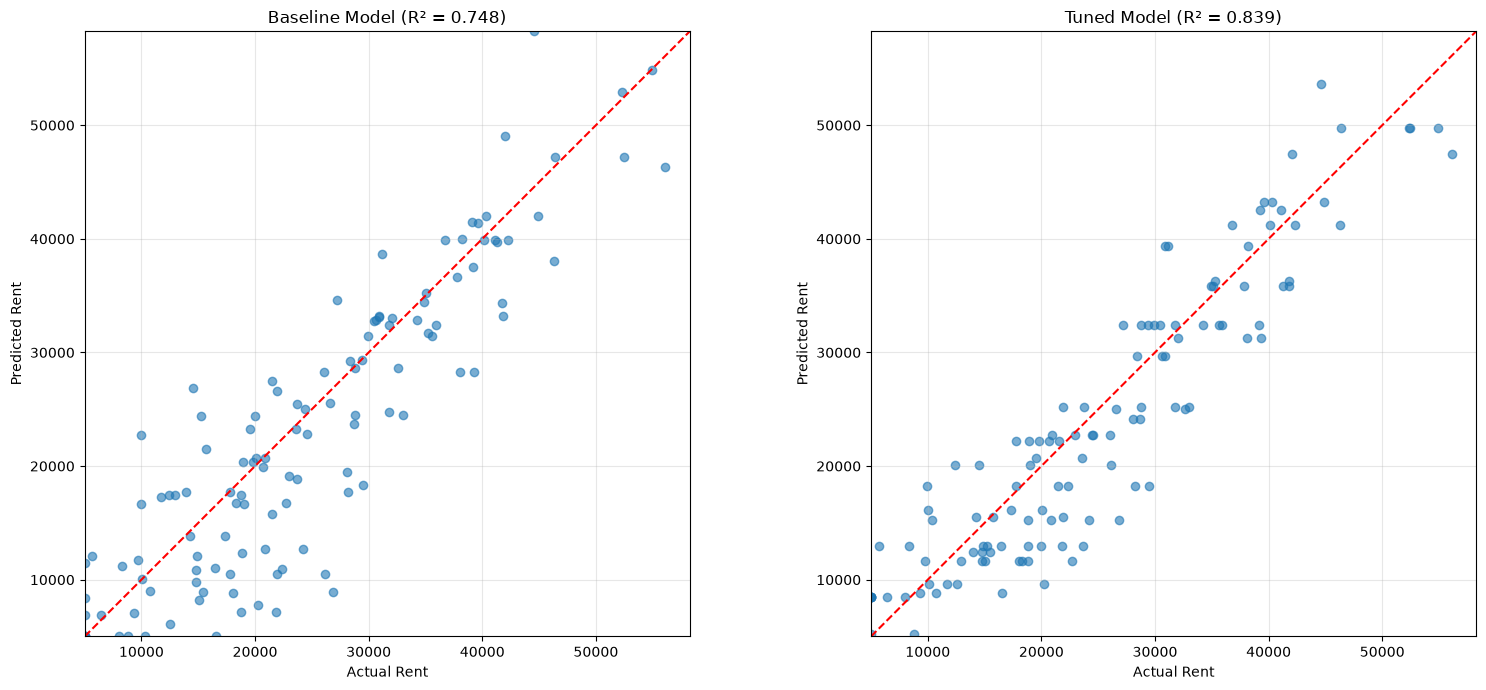

In [14]:
import matplotlib.pyplot as plt


### 建立圖表
fig, axes = plt.subplots(1, 2, figsize=(16, 7))


### 設定共同座標範圍
min_value = min(y_test.min(), y_test_pred.min(), y_test_best_pred.min())
max_value = max(y_test.max(), y_test_pred.max(), y_test_best_pred.max())


### Baseline Model
axes[0].scatter(
    y_test,
    y_test_pred,
    alpha=0.6
)

axes[0].plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--"
)

axes[0].set_title(f"Baseline Model (R² = {test_r2:.3f})")
axes[0].set_xlabel("Actual Rent")
axes[0].set_ylabel("Predicted Rent")
axes[0].grid(alpha=0.3)


### GridSearchCV Best Model
axes[1].scatter(
    y_test,
    y_test_best_pred,
    alpha=0.6
)

axes[1].plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--"
)

axes[1].set_title(f"Tuned Model (R² = {best_test_r2:.3f})")
axes[1].set_xlabel("Actual Rent")
axes[1].set_ylabel("Predicted Rent")
axes[1].grid(alpha=0.3)


### 統一座標軸
for ax in axes:
    ax.set_xlim(min_value, max_value)
    ax.set_ylim(min_value, max_value)
    ax.set_aspect("equal", adjustable="box")


### 調整版面
plt.tight_layout()
plt.show()

從圖中可以看到，Tuned Model 的散點整體更接近紅色虛線，R² 也從 0.748 提升至 0.839。

## 作業：使用 Logistic Regression 與 GridSearchCV 預測臺灣房屋是否屬於高單價住宅

本次作業使用政府資料開放平臺提供的「個人購置房屋契約價格資料(已去識別化)」，並使用 Logistic Regression (邏輯迴歸) 建立二元分類模型，判斷住宅是否屬於高單價住宅。

- 資料集：[個人購置房屋契約價格資料(已去識別化)](https://data.gov.tw/dataset/11724)
- 資料提供機關：金融監督管理委員會銀行局
- 資料格式：ZIP (內含資料檔案)

政府資料集包含建坪、屋齡、建物類別、鄉鎮市區、含車位價格等欄位，適合用來練習住宅價格分類。

這份資料同時包含彙總統計與不同層級的房價資訊，因此學生必須選擇具有完整住宅特徵及契約單價的資料紀錄，不能將不同統計層級的資料直接混合訓練。

### 預測目標

模型根據房屋的基本條件，例如：

```
建坪
屋齡
建物類別
鄉鎮市區
含車位價格 (類別資訊)
```

預測：

```
0：一般單價住宅
1：高單價住宅
```

本次作業暫時將每坪契約單價 30 萬元作為分類門檻：

$$y= \begin{cases} 1, & \text{契約單價}\geq 30\text{ 萬元/坪}\\\ 0, & \text{契約單價}<30\text{ 萬元/坪} \end{cases} $$

這是教學用門檻，不代表官方對高價住宅的定義。

建立以下關係：

$$ \boxed{ \text{房屋基本條件} \longrightarrow \text{Logistic Regression} \longrightarrow \text{預測是否為高單價住宅} } $$

本次作業重點不只是建立 Logistic Regression，還要使用 K-Fold Cross Validation 與 GridSearchCV，觀察不同超參數對分類表現的影響。

### 作業要求

學生必須按照以下順序完成：

```
1. Pandas 讀取政府開放資料
        ↓
2. 探索資料 (EDA)
   head / info / describe / isnull
        ↓
3. 資料清理 (Data Cleaning)
   處理缺失值、重複資料及欄位型態
        ↓
4. 建立二元分類 Target
   契約單價 >= 30 → 1
   契約單價 < 30  → 0
        ↓
5. 選擇 Features 與 Target
   排除契約單價及直接洩漏答案的欄位
        ↓
6. Train / Test Split
   80% / 20%
   stratify=y
        ↓
7. 建立資料前處理 Pipeline
   SimpleImputer
   StandardScaler
   OneHotEncoder
        ↓
8. 建立 Baseline Logistic Regression
        ↓
9. 訓練 Baseline Model
        ↓
10. K-Fold Cross Validation
    使用 StratifiedKFold (5-Fold)
        ↓
11. Hyperparameter Tuning
    設定 C、class_weight
        ↓
12. GridSearchCV
    自動搜尋最佳參數
        ↓
13. 使用最佳模型進行預測
        ↓
14. 評估模型表現
    Accuracy / Precision / Recall / F1
        ↓
15. 視覺化
    Confusion Matrix
        ↓
16. 比較 Baseline 與 Tuned Model
```

### GridSearchCV 指定參數

請使用以下搜尋範圍：

```python
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"]
}
```
Logistic Regression 使用：

```python
LogisticRegression(
    max_iter=1000,
    random_state=42
)
```

GridSearchCV 指定：

```py
GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    refit=True
)
```

因為這是二元分類問題，且高單價與一般單價住宅的數量可能不相同，因此本次使用 F1-score 作為主要搜尋指標。